
--- water_0 ---
Number of data points: 2532
x range: 20.00 – 70.62
y range: -0.11 – 8.59

--- f4_0 ---
Number of data points: 2532
x range: 20.00 – 70.62
y range: -0.11 – 3.87

--- f5_0 ---
Number of data points: 2532
x range: 20.00 – 70.62
y range: -0.11 – 2.66


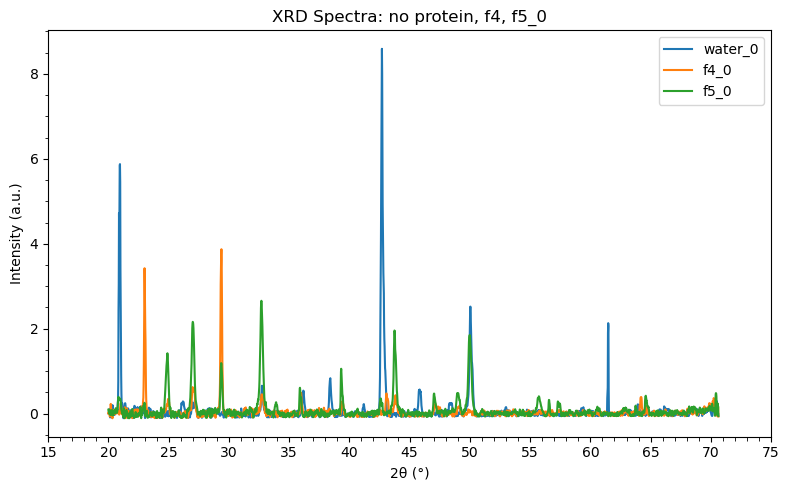

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "water_0": "/home/pkwon2/aragonite/raman/water_0.xy",
    "f4_0": "/home/pkwon2/aragonite/raman/f4_0.xy",
    "f5_0": "/home/pkwon2/aragonite/raman/f5_0.xy"
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    # Load data
    data = np.loadtxt(path)

    # Split into x and y
    x = data[:, 0]
    y = data[:, 1]

    # Restrict to x >= 20
    mask = x >= 20
    x = x[mask]
    y = y[mask]

    # Print basic stats
    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    # Plot
    plt.plot(x, y, label=label)

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra: no protein, f4, f5_0")
plt.legend()

# Tick marks every 5°
xmin, xmax = plt.xlim()
plt.xticks(np.arange(np.floor(xmin / 5) * 5, np.ceil(xmax / 5) * 5 + 1, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "array": "/home/pkwon2/aragonite/raman/array_2.5mMcaco3_2hr.xy",
    "no_protein": "/home/pkwon2/aragonite/raman/no_protein_2.5mMcaco3_2hr_sparse.xy",
    "si": "/home/pkwon2/aragonite/raman/si_wafer.xy"
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    # Load data
    data = np.loadtxt(path)

    # Split into x and y
    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 60
    mask = (x >= 20) & (x <= 80)
    x = x[mask]
    y = y[mask]

    # Print basic stats
    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    # Plot
    plt.plot(x, y, label=label)

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

# Major ticks every 5°
plt.xticks(np.arange(20, 80, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save high-resolution outputs (raster + vector)
out_base = "xrd_array_vs_no_protein"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")  # vector, best for papers

plt.show()


--- array ---
Number of data points: 2632
x range: 20.00 – 72.62
y range: -0.10 – 5.16

--- no_protein ---
Number of data points: 2632
x range: 20.00 – 72.62
y range: -0.11 – 2.76

--- si ---
Number of data points: 2560
x range: 20.00 – 71.18
y range: -0.10 – 0.40



--- array ---
Number of data points: 2001
x range: 20.00 – 60.00
y range: -0.10 – 5.16

--- no_protein ---
Number of data points: 2001
x range: 20.00 – 60.00
y range: -0.11 – 2.76

--- si_wafer ---
Number of data points: 2001
x range: 20.00 – 60.00
y range: -0.10 – 0.16


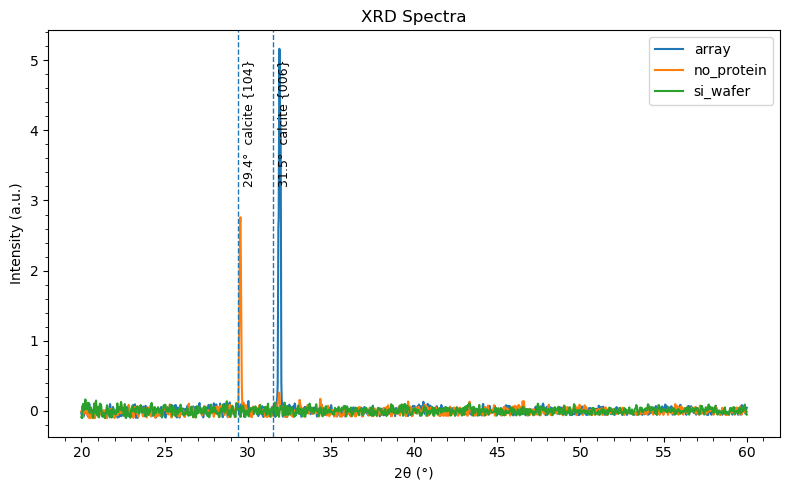

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "array": "/home/pkwon2/aragonite/raman/array_2.5mMcaco3_2hr.xy",
    "no_protein": "/home/pkwon2/aragonite/raman/no_protein_2.5mMcaco3_2hr_sparse.xy",
    "si_wafer": "/home/pkwon2/aragonite/raman/si_wafer.xy",
}

# Calcite facet reference lines (2θ, degrees)
calcite_refs = [
    (29.4, r"calcite {104}"),
    (31.5, r"calcite {006}"),
]

plt.figure(figsize=(8, 5))

ymax_seen = -np.inf

for label, path in file_paths.items():
    # Load data
    data = np.loadtxt(path)

    # Split into x and y
    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 60
    mask = (x >= 20) & (x <= 60)
    x = x[mask]
    y = y[mask]

    # Track max y for label placement
    if len(y) > 0:
        ymax_seen = max(ymax_seen, np.max(y))

    # Print basic stats
    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    # Plot
    plt.plot(x, y, label=label)

# --- Add vertical reference lines + labels ---
if not np.isfinite(ymax_seen):
    ymax_seen = 1.0  # fallback in case something went wrong / empty data

label_y = 0.97 * ymax_seen  # near the top
for x0, txt in calcite_refs:
    plt.axvline(x0, linestyle="--", linewidth=1)
    plt.text(
        x0 + 0.25,          # shift right of the line
        label_y,
        txt,
        rotation=90,
        va="top",
        ha="left",
        fontsize=9,
        clip_on=True
    )

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

# Major ticks every 5°
plt.xticks(np.arange(20, 61, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save high-resolution outputs (raster + vector)
out_base = "xrd_array_vs_no_protein_vs_si_wafer"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")  # vector, best for papers

plt.show()


--- si_wafer ---
Number of data points: 2001
x range: 20.00 – 60.00
peak max (raw): 0.1620
peak max (shown, clipped): 0.1620

--- no_protein ---
Number of data points: 2001
x range: 20.00 – 60.00
peak max (raw): 28.3737
peak max (shown, clipped): 0.4000

--- array ---
Number of data points: 2001
x range: 20.00 – 60.00
peak max (raw): 5.1637
peak max (shown, clipped): 0.4000


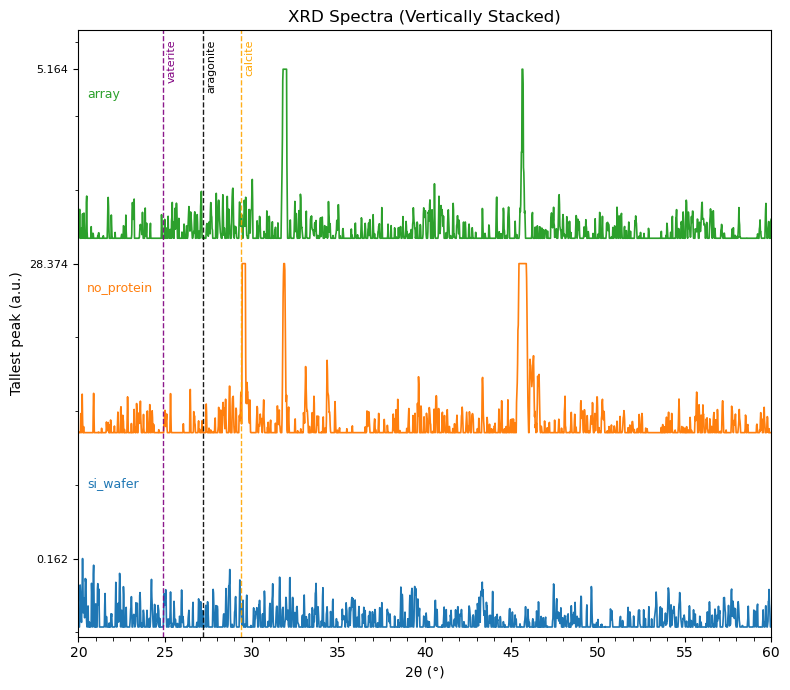

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra (order here = top-to-bottom order in the plot)
file_paths = {
    "array": "/home/pkwon2/aragonite/raman/array_2.5mMcaco3_2hr.xy",
    "no_protein": "/home/pkwon2/aragonite/raman/no_protein_2.5mMcaco3_2hr_sparse.xy",
    "si_wafer": "/home/pkwon2/aragonite/raman/si_wafer.xy",
}

# Reference peak positions (2θ, degrees)
vaterite_peaks  = [24.9]
aragonite_peaks = [27.2]
calcite_peaks   = [29.4]

# ---- plotting settings ----
x_min, x_max = 20, 60
y_min, y_max = 0.0, 0.4
offset = (y_max - y_min) * 1.15  # vertical gap between stacked spectra

labels = list(file_paths.keys())
n = len(labels)

plt.figure(figsize=(8, 7))

# Colors for the 4 spectra
cmap = plt.get_cmap("tab10")
trace_colors = [cmap(i) for i in range(n)]

ax = plt.gca()

# We'll put one y-tick per spectrum at the tallest (displayed) peak height,
# and label it with the *raw* tallest peak value (before clipping).
ytick_pos = []
ytick_lbl = []

# Plot stacked traces (reverse so first item appears on top)
for i, label in enumerate(labels[::-1]):
    path = file_paths[label]
    data = np.loadtxt(path)

    x = data[:, 0]
    y = data[:, 1]

    # Restrict to x-range
    mask = (x >= x_min) & (x <= x_max)
    x = x[mask]
    y = y[mask]

    # Tallest peak (raw, before clipping)
    peak_raw = float(np.max(y)) if len(y) else np.nan

    # Clip: 0 <= y <= 0.4 (for plotting)
    y = np.clip(y, y_min, y_max)

    # Tallest peak actually shown (after clipping)
    peak_shown = float(np.max(y)) if len(y) else np.nan

    # Apply vertical stacking offset
    y_stacked = y + i * offset

    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"peak max (raw): {peak_raw:.4f}")
    print(f"peak max (shown, clipped): {peak_shown:.4f}")

    ax.plot(x, y_stacked, lw=1.2, color=trace_colors[i])
    ax.text(
        x_min + 0.5,
        i * offset + (y_max * 0.85),
        label,
        va="center",
        fontsize=9,
        color=trace_colors[i],
    )

    # Add a y-axis tick at the tallest shown peak position, label with raw peak height
    if len(y):
        ytick_pos.append(i * offset + peak_shown)
        ytick_lbl.append(f"{peak_raw:.3f}")

# Add reference peak markers
y_top = (n - 1) * offset + y_max

def add_peak_lines(peaks, phase_label, color, linestyle="--", dx=0.18, y_frac=0.985):
    """
    dx: shift label to the right of the line (in degrees 2θ)
    y_frac: vertical position in axes coords (0..1), keeps text inside the box
    """
    for p in peaks:
        ax.axvline(p, color=color, linestyle=linestyle, lw=1.0, alpha=0.9)

    for p in peaks:
        if x_min <= p <= x_max:
            ax.text(
                p + dx, y_frac, phase_label,
                transform=ax.get_xaxis_transform(),  # x in data units, y in axes fraction
                rotation=90,
                va="top", ha="left",
                fontsize=8, color=color,
                clip_on=True
            )
            break

add_peak_lines(vaterite_peaks,  "vaterite",  color="purple", linestyle="--")
add_peak_lines(aragonite_peaks, "aragonite", color="black",  linestyle="--")
add_peak_lines(calcite_peaks,   "calcite",   color="orange", linestyle="--")

ax.set_xlabel("2θ (°)")
ax.set_ylabel("Tallest peak (a.u.)")  # tick labels are per-spectrum tallest peak values (raw)

ax.set_title("XRD Spectra (Vertically Stacked)")

ax.set_xlim(x_min, x_max)
ax.set_ylim(-0.05 * offset, y_top + 0.20 * offset)

ax.set_xticks(np.arange(20, 65, 5))
ax.minorticks_on()
ax.tick_params(axis="x", which="minor", length=3)

# Put one y-tick per trace at its tallest (shown) peak, labeled with the raw tallest peak value
ax.set_yticks(ytick_pos)
ax.set_yticklabels(ytick_lbl, fontsize=8)

plt.tight_layout()

out_base = "aragonite_stacked_with_peaks"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")

plt.show()


--- no_protein ---
Number of data points: 1251
x range: 20.00 – 45.00
y range: -0.11 – 4.34


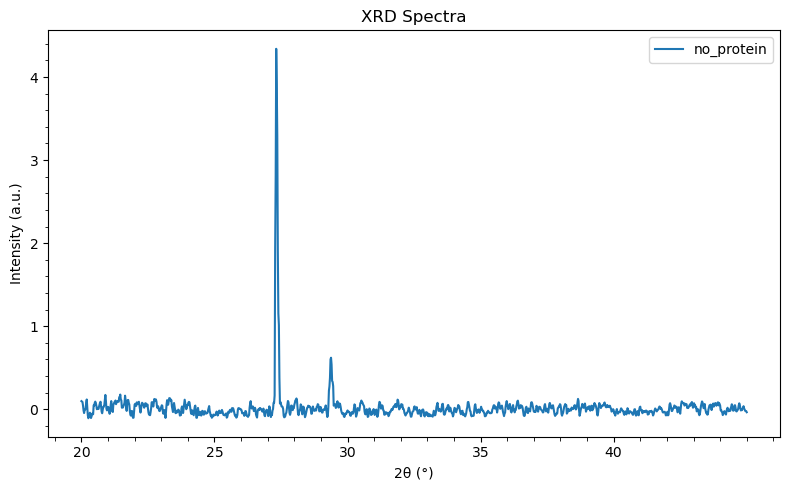

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    # "bsa": "/home/pkwon2/aragonite/raman/bsa.xy",
    "no_protein": "/home/pkwon2/aragonite/raman/water_5mM_caco3.xy",
    # "f4": "/home/pkwon2/aragonite/raman/f4_5mM_caco3.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    # Load data
    data = np.loadtxt(path)

    # Split into x and y
    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 45
    mask = (x >= 20) & (x <= 45)
    x = x[mask]
    y = y[mask]

    # Print basic stats
    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    # Plot
    plt.plot(x, y, label=label)

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

# Major ticks every 5°
plt.xticks(np.arange(20, 45, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save high-resolution outputs (raster + vector)
out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")  # vector, best for papers

plt.show()


--- bsa ---
Number of data points: 2251
x range: 20.00 – 65.00
y range: -0.11 – 0.31

--- no_protein ---
Number of data points: 2251
x range: 20.00 – 65.00
y range: -0.11 – 4.34

--- f4 ---
Number of data points: 2251
x range: 20.00 – 65.00
y range: -0.11 – 7.31

--- f5 ---
Number of data points: 2251
x range: 20.00 – 65.00
y range: -0.11 – 0.36

--- f5_0 ---
Number of data points: 2251
x range: 20.00 – 65.00
y range: -0.11 – 0.18


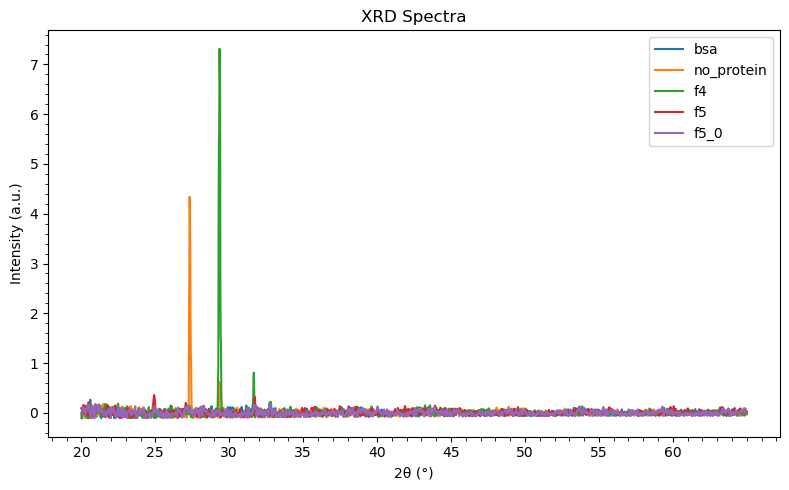

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "bsa": "/home/pkwon2/aragonite/raman/bsa.xy",
    "no_protein": "/home/pkwon2/aragonite/raman/water_5mM_caco3.xy",
    "f4": "/home/pkwon2/aragonite/raman/f4_5mM_caco3.xy",
    "f5": "/home/pkwon2/aragonite/raman/f5_1_5mMcaco3_80C_1h.xy",
    "f5_0": "/home/pkwon2/aragonite/raman/f5_4.xy",
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    # Load data
    data = np.loadtxt(path)

    # Split into x and y
    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 45
    mask = (x >= 20) & (x <= 65)
    x = x[mask]
    y = y[mask]

    # Print basic stats
    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    # Plot
    plt.plot(x, y, label=label)

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

# Major ticks every 5°
plt.xticks(np.arange(20, 65, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save high-resolution outputs (raster + vector)
out_base = "aragonite"
plt.savefig(f"{out_base}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{out_base}.pdf", bbox_inches="tight")  # vector, best for papers

plt.show()

##### import numpy as np
import matplotlib.pyplot as plt

# File paths for all spectra
file_paths = {
    "water_0": "/home/pkwon2/aragonite/raman/water_0.xy",
    "f5_0": "/home/pkwon2/aragonite/raman/f5.xy"
}

plt.figure(figsize=(8, 5))

for label, path in file_paths.items():
    # Load data
    data = np.loadtxt(path)

    # Split into x and y
    x = data[:, 0]
    y = data[:, 1]

    # Restrict to 20 ≤ x ≤ 60
    mask = (x >= 24) & (x <= 60)
    x = x[mask]
    y = y[mask]

    # Print basic stats
    print(f"\n--- {label} ---")
    print(f"Number of data points: {len(x)}")
    print(f"x range: {x.min():.2f} – {x.max():.2f}")
    print(f"y range: {y.min():.2f} – {y.max():.2f}")

    # Plot
    plt.plot(x, y, label=label)

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectra")
plt.legend()

# Major ticks every 5°
plt.xticks(np.arange(24, 61, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()
plt.show()


--- aragonite DHR ---
Number of data points: 1801
x range: 24.00 – 60.00
y range: -0.10 – 19.71


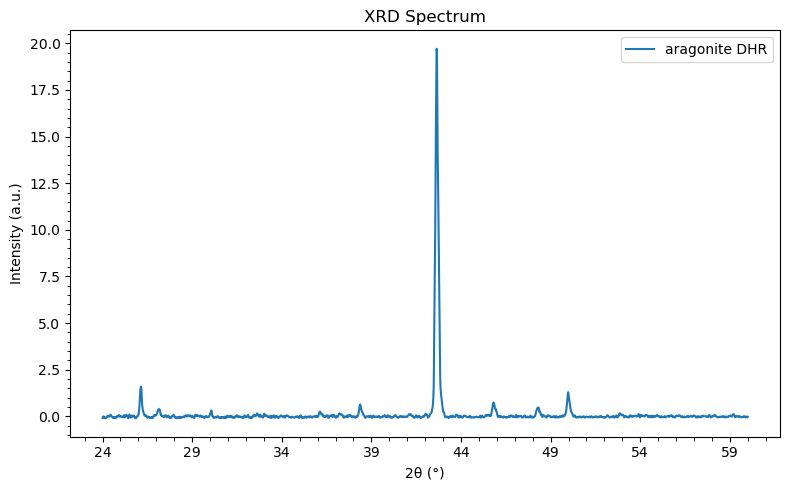

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# File path for just f5
file_path = "/home/pkwon2/aragonite/raman/water_2.xy"
label = "aragonite DHR"

# Load data
data = np.loadtxt(file_path)

# Split into x and y
x = data[:, 0]
y = data[:, 1]

# Restrict to 24 ≤ x ≤ 60
mask = (x >= 24) & (x <= 60)
x = x[mask]
y = y[mask]

# Print basic stats
print(f"\n--- {label} ---")
print(f"Number of data points: {len(x)}")
print(f"x range: {x.min():.2f} – {x.max():.2f}")
print(f"y range: {y.min():.2f} – {y.max():.2f}")

# Plot
plt.figure(figsize=(8, 5))
plt.plot(x, y, label=label)

# Labels and title
plt.xlabel("2θ (°)")
plt.ylabel("Intensity (a.u.)")
plt.title("XRD Spectrum")
plt.legend()

# Major ticks every 5°
plt.xticks(np.arange(24, 61, 5))

# Minor ticks every 1°
plt.minorticks_on()
plt.tick_params(axis="x", which="minor", length=3)

plt.tight_layout()

# Save as PNG
plt.savefig("f4.png", dpi=300, bbox_inches="tight")

plt.show()